In [5]:
from tkinter import Image

import autograd
from autograd import numpy as anp, value_and_grad
import matplotlib.pyplot as plt
import problems
import topo_physics
import topo_api
import torch
import torch.nn as nn

import nlopt

from tqdm import tqdm, trange

problem = problems.comparison_problem(height=80, width=120)

# --------------------------
# Pixel-based model using numpy + autograd
# --------------------------
class PixelModel:
    def __init__(self, args, seed=None):
        self.seed = seed
        if seed is not None:
            anp.random.seed(seed)
        self.env = topo_api.Environment(args)
        self.nely = self.env.args['nely']
        self.nelx = self.env.args['nelx']
        self.volfrac = self.env.args['volfrac']
        
        # z is the design variable, initialized to the volume fraction
        # however, in our settings, we want to find f(z,shape) = x

        # design variable
        self.z = anp.ones((self.nely, self.nelx)) * self.volfrac

    def get_design(self):
        """
        forward: latent z -> density field x
        """
        return self.z



def update_plot(z, iter_num=None):
    global im
    if im is None:
        im = ax.imshow(z, cmap='gray_r', origin='lower', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax)
    else:
        im.set_data(z)

    title = f"Iteration {iter_num}" if iter_num is not None else "Design"
    ax.set_title(title)

    fig.canvas.draw_idle()
    fig.canvas.flush_events() 

def run_mma_visual(model, max_iterations=50, refresh_every=1):
    env = model.env
    x0 = model.get_design().ravel().astype(anp.float64)

    losses = []
    frames = [x0.copy()]

    # Interactive plot
    plt.ion()
    fig, ax = plt.subplots()
    im = ax.imshow(env.reshape(frames[0]), cmap='viridis', origin='lower', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)


    ####################################################
    ## todo
    ## change mapping and inverse mapping to something
    ## more complex, e.g. a small MLP
    ####################################################
    def mapping(z):
        # example mapping, can be changed to something more complex
        # return z**2 * np.sin(z)
        return z

    def wrap_autograd_func(func, losses=None, frames=None):
        def wrapper(x, grad):
            def mapped_func(x):
                x_mapped = mapping(x)
                return func(x_mapped)
            value, g = autograd.value_and_grad(mapped_func)(x)
            if grad.size > 0:
                grad[:] = g.ravel()
            if losses is not None:
                losses.append(value)
            if frames is not None:
                frames.append(x.copy())
            return value
        return wrapper


    # Define objective and constraint
    objective_fn = lambda x: env.objective(x, volume_constraint=False)
    constraint_fn = lambda x: env.constraint(x)

    opt = nlopt.opt(nlopt.LD_MMA, x0.size)
    opt.set_lower_bounds(0.0)
    opt.set_upper_bounds(1.0)
    opt.set_min_objective(wrap_autograd_func(objective_fn, losses, frames))
    opt.add_inequality_constraint(wrap_autograd_func(constraint_fn), 1e-8)
    opt.set_maxeval(max_iterations)
    opt.set_xtol_rel(1e-6)
    opt.set_xtol_abs(1e-8)


    x_opt = opt.optimize(x0)  # start optimization from a transformed design variable

    for i, x in enumerate(frames[1:], start=1):
        x_mapped = mapping(x)
        im.set_data(env.reshape(x_mapped))
        
        ax.set_title(f"MMA iteration: {i+1}, loss: {losses[i-1]:.6f}")
        plt.pause(0.01)

    plt.ioff()
    plt.show()

    designs = [env.reshape(f) for f in frames]
    return losses, designs

def run_oc_visual(model, max_iterations=50, refresh_every=1):
    env = model.env
    x = model.z.ravel().astype(anp.float64)

    losses = []
    frames = [x.copy()]

    update_plot(env.reshape(x), iter_num=0)

    for it in range(max_iterations):
        c, x_next = topo_physics.optimality_criteria_step(x, env.ke, env.args)

        if anp.isnan(c):
            print(f"NaN encountered at iteration {it}, stopping.")
            break

        losses.append(c)
        x = x_next
        frames.append(x.copy())

        if it % refresh_every == 0 or it == max_iterations - 1:
            update_plot(env.reshape(x), iter_num=it+1)

        if it % 10 == 0:
            print(f"Iteration {it}: compliance = {c:.6f}")

    final_c = env.objective(x, volume_constraint=False)
    losses.append(final_c)
    print(f"Final compliance: {final_c:.6f}")

    plt.ioff()
    plt.show()

    designs = [env.reshape(f) for f in frames]
    return losses, designs


# prototype
def run_mma_prototype(env, max_iterations=50, refresh_every=1):
    nely, nelx = problem.height, problem.width
    x0 = anp.array([10.0, 10.0, 0.0, 0.0, 0.0], dtype=anp.float64)

    losses = []
    frames = []

    def density_field_full(x_var, nely=50, nelx=100):
        w, h, theta, tx, ty = x_var
        x = anp.arange(nelx)
        y = anp.arange(nely)
        xv, yv = anp.meshgrid(x, y)
        cx = nelx / 2 + tx
        cy = nely / 2 + ty
        xt = xv - cx
        yt = yv - cy
        cos_t = anp.cos(theta)
        sin_t = anp.sin(theta)
        x_rot = cos_t * xt + sin_t * yt
        y_rot = -sin_t * xt + cos_t * yt
        dx = x_rot / (w / 2)
        dy = y_rot / (h / 2)
        r2 = dx**2 + dy**2
        sigma = 1.0
        field = anp.exp(-r2 / (2 * sigma**2))
        return field.ravel()

    plt.ion()
    fig, ax = plt.subplots()
    dens = density_field_full(x0, nely=nely, nelx=nelx)
    im = ax.imshow(dens.reshape(nely, nelx), cmap='viridis', origin='lower', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)

    def objective_fn(x_var):
        dens = density_field_full(x_var, nely=nely, nelx=nelx)
        return env.objective(dens, volume_constraint=False)

    def wrap_autograd_func(func, losses=None, frames=None):
        def wrapper(x, grad_out):
            value, g = value_and_grad(func)(x)
            if grad_out.size > 0:
                grad_out[:] = g.ravel()
            if losses is not None:
                losses.append(value)
            if frames is not None:
                frames.append(x.copy())
            return value
        return wrapper

    opt = nlopt.opt(nlopt.LD_MMA, 5)
    opt.set_lower_bounds([1.0, 1.0, -np.pi/4, -nelx/2, -nely/2])
    opt.set_upper_bounds([nelx*0.9, nely*0.9, np.pi/4, nelx/2, nely/2])
    opt.set_min_objective(wrap_autograd_func(objective_fn, losses, frames))
    opt.set_maxeval(max_iterations)
    opt.set_xtol_rel(1e-6)
    opt.set_xtol_abs(1e-8)

    x_opt = opt.optimize(x0)

    for i, x_var in enumerate(frames):
        dens = density_field_full(x_var, nely=nely, nelx=nelx)
        im.set_data(dens.reshape(nely, nelx))
        ax.set_title(f"Iteration {i+1}, Loss: {losses[i]:.6f}")
        plt.pause(0.05)

    plt.ioff()
    plt.show()

    designs = [density_field_full(f, nely=nely, nelx=nelx).reshape(nely, nelx) for f in frames]
    return losses, designs

def volume_penalty_points_fn(x_var, n_points, nely=50, nelx=100):
    dens = density_field_points_sigma(x_var, n_points, nely=nely, nelx=nelx)
    overflow = anp.maximum(dens - 1.0, 0.0)
    return anp.sum(overflow**2)

def density_field_points_sigma(x_var, n_points, nely, nelx):
    field = anp.zeros((nely, nelx))

    x = anp.arange(nelx)
    y = anp.arange(nely)
    xv, yv = anp.meshgrid(x, y)
    for i in range(n_points):
        tx, ty, sigma = x_var[3*i:3*i+3]
        sigma = 1
        cx = nelx/2 + tx
        cy = nely/2 + ty
        r2 = (xv-cx)**2 + (yv-cy)**2
        field += anp.exp(-r2/(2*sigma**2))

    # field = anp.clip(field,0,1)

    return field.ravel()

def run_mma_prototype_points_sigma(env, n_points=10, max_iterations=50):
    nely, nelx = env.args['nely'], env.args['nelx']
    x0 = []

    for i in range(n_points):
        tx = anp.random.uniform(-nelx/2, nelx/2)
        ty = anp.random.uniform(-nely/2, nely/2)
        sigma = 1.0
        x0.extend([tx,ty,sigma])

    x0 = anp.array(x0,dtype=anp.float64)
    losses=[]
    frames=[]

    plt.ion()
    fig,ax = plt.subplots()

    dens = density_field_points_sigma(x0,n_points,nely,nelx)
    im = ax.imshow(dens.reshape(nely,nelx),
                   cmap='viridis',
                   origin='lower',
                   vmin=0,
                   vmax=1)
    fig.colorbar(im,ax=ax)

    def objective_fn(x_var):
        dens = density_field_points_sigma(x_var,n_points,nely,nelx)
        return env.objective(dens,volume_constraint=False) + volume_penalty_points_fn(x_var, n_points, nely, nelx)

    def wrap_autograd_func(func):
        def wrapper(x,grad):
            value,g = value_and_grad(func)(x)
            if grad.size>0:
                grad[:] = g
            dens = density_field_points_sigma(x, n_points, nely, nelx)
            true_value = env.objective(dens, volume_constraint=False)
            losses.append(true_value)
            # losses.append(value)
            frames.append(x.copy())
            return value
        return wrapper

    opt = nlopt.opt(nlopt.LD_MMA,3*n_points)
    lower=[]
    upper=[]

    for i in range(n_points):
        lower.extend([-nelx/2,-nely/2,0.1])
        upper.extend([ nelx/2, nely/2,8.0])

    opt.set_lower_bounds(lower)
    opt.set_upper_bounds(upper)
    opt.set_min_objective(wrap_autograd_func(objective_fn))
    opt.set_maxeval(max_iterations)

    x_opt = opt.optimize(x0)

    for i,x_var in enumerate(frames):
        dens = density_field_points_sigma(x_var,n_points,nely,nelx)
        im.set_data(dens.reshape(nely,nelx))
        ax.set_title(f"Iter {i} Loss {losses[i]:.4f}")
        print(f"volume fraction at iter {i}: {anp.mean(dens):.4f}/{env.args['volfrac']:.4f}")
        plt.pause(0.05)

    plt.ioff()
    plt.show()
    designs = [
        density_field_points_sigma(f,n_points,nely,nelx).reshape(nely,nelx)
        for f in frames
    ]

    return losses,designs,frames[-1]

def target_region_penalty_fn(x_var, n_points,target_region_dens, nely=50, nelx=100):
    dens = density_field_n_shapes_sigma(x_var, n_points, nely=nely, nelx=nelx)
    return anp.sum((dens - target_region_dens)**2)

def density_field_n_shapes_sigma(x_var, n_shapes, nely=50, nelx=100):
    field_total = anp.zeros(nely*nelx)

    for i in range(n_shapes):
        xi = x_var[i*6:(i+1)*6]
        w, h, theta, tx, ty, sigma = xi
        sigma = 1
        w = 3
        # if i%2 == 0:
        #     h = 15
        # else:
        #     h = 30
        h = 25

        # if i == 0:
        # if i  == 0:
        #     theta = np.pi * 0.5
        #     tx = 20 - nelx / 2
        #     ty = 40 - nely / 2
        # if i == 1:
        #     theta = np.pi * 0.5
        #     tx = 60 - nelx / 2
        #     ty = 40 - nely / 2
        # if i == 2:
        #     theta = np.pi * 0.25
        #     tx = 20 - nelx / 2
        #     ty = 20 - nely / 2
        # if i == 3:
        #     theta = 0
        #     tx = 40 - nelx / 2
        #     ty = 20 - nely / 2
        # if i == 4:
        #     theta = np.pi * -0.25
        #     tx = 60 - nelx / 2
        #     ty = 20 - nely / 2
        # if i == 5:
        #     theta = np.pi * 0.5
        #     tx = 20 - nelx / 2
        #     ty = 0 - nely / 2
    
        x = anp.arange(nelx)
        y = anp.arange(nely)
        xv, yv = anp.meshgrid(x, y)
        cx = nelx / 2 + tx
        cy = nely / 2 + ty
        xt = xv - cx
        yt = yv - cy
        cos_t = anp.cos(theta)
        sin_t = anp.sin(theta)
        x_rot = cos_t * xt + sin_t * yt
        y_rot = -sin_t * xt + cos_t * yt
        dx = x_rot / (w / 2)
        dy = y_rot / (h / 2)
        r2 = dx**2 + dy**2
        field = anp.exp(-r2 / (2 * sigma**2))
        field_total += field.ravel()

    # field_total = anp.clip(field_total, 0, 1)
    return field_total


def volume_constraint_fn(x_var, n_shapes, nely=50, nelx=100, max_fraction=0.3):
    dens = density_field_n_shapes_sigma(x_var, n_shapes, nely=nely, nelx=nelx)
    max_allowed = max_fraction * nely * nelx
    return (anp.sum(dens) - max_allowed)**2

def initialize_shapes_from_mma(dens, n_shapes, w=10, h=10, sigma=1):
    nely, nelx = dens.shape
    candidates = anp.argwhere(dens > 0.95)
    if len(candidates) < n_shapes:
        raise ValueError("structure too sparse to initialize the desired number of shapes.")
    chosen_idx = anp.random.choice(len(candidates), n_shapes, replace=False)
    centers = candidates[chosen_idx]
    
    x0 = []
    for cy, cx in centers:
        theta = 0.0
        tx = cx - nelx/2
        ty = cy - nely/2
        x0.extend([w, h, theta, tx, ty, sigma])
    return anp.array(x0, dtype=anp.float64)

def volume_penalty_shapes_fn(x_var, n_shapes, nely=50, nelx=100):
    dens = density_field_n_shapes_sigma(x_var, n_shapes, nely=nely, nelx=nelx)
    overflow = anp.maximum(dens - 1.0, 0.0)
    # overflow = overflow + (overflow > 0).astype(float)
    return anp.sum(overflow**2)

def run_mma_translation_n_shapes_sigma(env, n_shapes=2, max_iterations=50, refresh_every=1, 
                                      max_volume_fraction=0.5, x0=None, initial_pos = None, target_region_dens=None):
    nely, nelx = env.args['nely'], env.args['nelx']
    if x0 is None:
        x0 = []
        for i in range(n_shapes):
            w_init = 2
            h_init = 35
            theta_init = 0.0
            sigma_init = 1
            tx_init = anp.random.uniform(-nelx/2 + w_init/2, nelx/2 - w_init/2)
            ty_init = anp.random.uniform(-nely/2 + h_init/2, nely/2 - h_init/2)
            if initial_pos is not None and i < len(initial_pos):
                tx_init, ty_init = initial_pos[i]

            # if i  == 0:
            #     theta_init = anp.pi * 0.5
            #     tx_init = 20 - nelx / 2
            #     ty_init = 40 - nely / 2
            # if i == 1:
            #     theta_init = anp.pi * 0.5
            #     tx_init = 60 - nelx / 2
            #     ty_init = 40 - nely / 2
            # if i == 2:
            #     theta_init = anp.pi * 0.25
            #     tx_init = 20 - nelx / 2
            #     ty_init = 20 - nely / 2
            # if i == 3:
            #     theta_init = 0
            #     tx_init = 40 - nelx / 2
            #     ty_init = 20 - nely / 2
            # if i == 4:
            #     theta_init = anp.pi * 0.75
            #     tx_init = 60 - nelx / 2
            #     ty_init = 20 - nely / 2
            # if i == 5:
            #     theta_init = anp.pi * 0.5
            #     tx_init = 20 - nelx / 2
            #     ty_init = 0 - nely / 2
            x0.extend([w_init, h_init, theta_init, tx_init, ty_init, sigma_init])
        x0 = anp.array(x0, dtype=anp.float64)
    

    losses = []
    frames = []

    plt.ion()
    fig, ax = plt.subplots()
    dens = density_field_n_shapes_sigma(x0, n_shapes, nely=nely, nelx=nelx)
    im = ax.imshow(dens.reshape(nely, nelx), cmap='viridis', origin='lower', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)

    def objective_fn(x_var):
        dens = density_field_n_shapes_sigma(x_var, n_shapes, nely=nely, nelx=nelx)
        anp.clip(dens, 0, 1)
        if target_region_dens is not None:
            return env.objective(dens, volume_constraint=False) + volume_penalty_shapes_fn(x_var, n_shapes, nely, nelx) + target_region_penalty_fn(x_var, n_shapes, target_region_dens, nely, nelx)
        return env.objective(dens, volume_constraint=False) + volume_penalty_shapes_fn(x_var, n_shapes, nely, nelx)

    def wrap_autograd_func(func):
        def wrapper(x, grad_out):
            value, g = value_and_grad(func)(x)
            if grad_out.size > 0:
                grad_out[:] = g.ravel()
            dens = density_field_n_shapes_sigma(x, n_shapes, nely, nelx)
            dens = anp.where(dens > 0.5, 1, dens)
            true_value = env.objective(dens, volume_constraint=False)
            losses.append(true_value)
            frames.append(anp.array(x, dtype=anp.float64))
            return value
        return wrapper

    # w, h, theta, tx, ty, sigma
    opt = nlopt.opt(nlopt.LD_MMA, 6*n_shapes)
    lower = [1.0,10,0,-nelx/2,-nely/2,0.1]*n_shapes
    upper = [nelx*0.9,35,anp.pi,nelx/2,nely/2,1]*n_shapes
    opt.set_lower_bounds(lower)
    opt.set_upper_bounds(upper)
    opt.set_min_objective(wrap_autograd_func(objective_fn))
    opt.set_maxeval(max_iterations)
    opt.set_xtol_rel(1e-6)
    opt.set_xtol_abs(1e-8)
    # opt.set_initial_step([1e1]*(6*n_shapes))
    # opt.add_inequality_constraint(wrap_autograd_func(lambda x: volume_constraint_fn(x, n_shapes, nely, nelx, max_volume_fraction)), 1e-8)

    x_opt = opt.optimize(x0)

    # for i, x_var in enumerate(frames):
    #     dens = density_field_n_shapes_sigma(x_var, n_shapes, nely=nely, nelx=nelx)
    #     im.set_data(dens.reshape(nely, nelx))
    #     ax.set_title(f"Iteration {i+1}, Loss: {losses[i]:.6f}")
    #     plt.pause(0.05)

    plt.ioff()
    plt.show()

    designs = [density_field_n_shapes_sigma(f, n_shapes, nely=nely, nelx=nelx).reshape(nely, nelx) for f in frames]
    return losses, designs

Iteration 0: compliance = 167.783759
Iteration 10: compliance = 11.922699
Iteration 20: compliance = 11.452972
Iteration 30: compliance = 11.396163
Iteration 40: compliance = 11.376410
Iteration 50: compliance = 11.360178
Iteration 60: compliance = 11.340555
Iteration 70: compliance = 11.310022
Iteration 80: compliance = 11.270372
Iteration 90: compliance = 11.241582
Final compliance: 11.210295


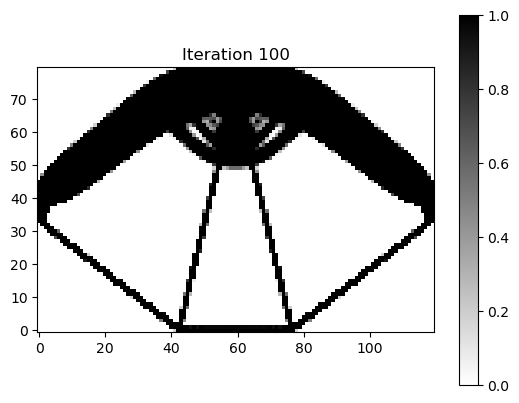

In [7]:
method = 'oc'  # 'oc' or 'mma' or 'prototype_n'
iterations = 100


args = topo_api.specified_task(problem)
model = PixelModel(args=args)  

plt.ion()  # turn on interactive mode
fig, ax = plt.subplots()
im = None

losses, designs = run_oc_visual(model, max_iterations=iterations, refresh_every=1)

opt_design = designs[-1]

# elif method == 'mma':
#     losses, designs = run_mma_visual(model, max_iterations=iterations, refresh_every=1)
#     plt.imsave("final_design_mma.png", designs[-1], cmap='gray_r', origin='lower')  
# elif method == 'prototype':
#     losses, designs = run_mma_prototype_points_sigma(model.env,200, max_iterations=iterations)
#     plt.imsave("final_design_prototype1000.png", designs[-1], cmap='gray_r', origin='lower')
#     plt.imsave("final_design_prototype500.png", designs[500], cmap='gray_r', origin='lower')
#     plt.imsave("final_design_prototype250.png", designs[250], cmap='gray_r', origin='lower')
#     plt.imsave("final_design_prototype100.png", designs[100], cmap='gray_r', origin='lower')
#     print(f"losses, final compliance1000: {losses[-1]:.6f}, final compliance500: {losses[500]:.6f}, final compliance250: {losses[250]:.6f}, final compliance100: {losses[100]:.6f}")
# elif method == 'prototype_n':
#     # losses_mma, designs_mma = run_mma_visual(model, max_iterations=iterations, refresh_every=1)
#     # dens_mma = designs_mma[-1]
#     # x0_init = initialize_shapes_from_mma(dens_mma, n_shapes)
#     n_shapes = 6
#     losses, designs = run_mma_translation_n_shapes_sigma(
#         model.env,
#         n_shapes=n_shapes,
#         max_iterations=iterations
#     )
#     x_final = designs[-1] 
#     volfrac_final = np.mean(x_final)
#     compliance_final = model.env.objective(x_final, volume_constraint=False)

  